# Interconnector outages: DK2 dispatch and resilience

Playground notebook. Helpers first, then one section per plot.

**Naming:** cluster names do not match the price zones. DK2 (Zealand) is bus `DK0 0AC`;
`DK2 0AC` is actually DK1 (Jutland).

**Sign convention for all balance plots:** above zero = supply into the region's buses,
below zero = use. Above and below sum to zero in every hour (checked below).
Load shedding is a virtual supply and sits on top of the supply stack (red, hatched).

In [1]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import pypsa
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch

from outage_helpers import *   # balance, grouping, colours (shared)

# ---- inputs ---------------------------------------------------------------
#NETWORK = Path("results/base_network/network_solved.nc")
NETWORK = Path("results/disruptions_3/network_solved.nc")
REGION = "DK0 0AC"       # DK2 (Zealand) = "DK0 0AC"
REGION_LABEL = "DK2"
RESAMPLE = "D"           # daily means
FIG_DIR = Path("results/plots_outage")
SHED_NOISE_MW = 0.1      # hourly shedding below this is solver noise and set to 0

# two-week windows for the hourly zoom plots (inclusive, Monday to Sunday)
ZOOM_WINDOWS = {
    "Summer": ("2013-07-08", "2013-07-21"),
    "Winter": ("2014-01-13", "2014-01-26"),
}

In [2]:
n = pypsa.Network(NETWORK)
print(n.snapshots[0], "->", n.snapshots[-1], f"({len(n.snapshots)} snapshots)")

INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.3)
INFO:pypsa.network.io:Imported network 'Unnamed Network' has buses, carriers, generators, global_constraints, lines, links, loads, storage_units, stores, sub_networks


2013-07-01 00:00:00 -> 2014-06-30 23:00:00 (8760 snapshots)


## Helpers: regional energy balance

Shared with the other outage notebooks, see `outage_helpers.py`.

In [3]:
# region_buses, injections, INTERCONNECTOR_NAMES, ... live in outage_helpers.py
INTERCONNECTOR_NAMES

{('DK0 0AC', 'SE0 0AC'): 'Øresund (SE)',
 ('DK0 0AC', 'DE2 0AC'): 'Kontek (DE)',
 ('DK0 0AC', 'DK2 0AC'): 'Great Belt (DK1)'}

### Grouping

First matching regex wins. Loads always go to the demand group, interconnectors get one
group per cable (forward + reversed link summed). Anything unmatched lands in "Other" and is
printed, so nothing disappears silently. Groups that are ~0 all year are not drawn, so
"Oil" and "Gas turbines" only show up when they actually run.

Rules, orders and colours are defined in `outage_helpers.py`.

In [4]:
# POWER_RULES / HEAT_RULES, SUPPLY_ORDER / USE_ORDER, colours and region_balance
# live in outage_helpers.py
COLORS = build_colors(n)

## Helpers: dispatch plot

In [5]:
def _ordered(cols, order, interconnectors):
    out = []
    for g in order:
        out += [c for c in interconnectors if c in cols] if g == "<interconnectors>" else [g] * (g in cols)
    return out + [c for c in cols if c not in out]


def _shedding_note(shed):
    shed = shed[shed > 0]
    if shed.empty:
        return "Load shedding: none"
    return (f"Load shedding: {shed.sum() / 1e3:,.1f} GWh, "
            f"peak {shed.max():,.0f} MW, {len(shed)} h")


def plot_balance(ax, bal, resample=RESAMPLE, min_mw=1.0):
    # Two-sided stacked area: supply above 0, use below 0. resample=None -> hourly.
    # Returns legend handles (supply top-down, then use).
    ics = [c for c in bal if c in INTERCONNECTOR_NAMES.values() or c.startswith("Interconnectors ")]
    pos, neg = bal.clip(lower=0), bal.clip(upper=0)
    if resample:
        pos, neg = pos.resample(resample).mean(), neg.resample(resample).mean()
    pos, neg = pos / 1e3, neg / 1e3   # GW
    pos = pos.loc[:, pos.max() * 1e3 >= min_mw]
    neg = neg.loc[:, neg.min() * 1e3 <= -min_mw]
    pos = pos[_ordered(pos.columns, SUPPLY_ORDER, ics)]
    neg = neg[_ordered(neg.columns, USE_ORDER, ics)]

    extra, ic_extra = iter(FALLBACK_COLORS), iter(IC_COLORS)
    color = {g: COLORS.get(g) or next(ic_extra if g in ics else extra)
             for g in dict.fromkeys([*pos, *neg])}
    x = pos.index
    for df in (pos, neg):
        if df.empty:
            continue
        polys = ax.stackplot(x, df.T.values, colors=[color[g] for g in df], linewidth=0)
        for g, poly in zip(df, polys):
            if g == "Load shedding":
                poly.set_hatch("////")
                poly.set_edgecolor("#7f0000")

    ax.axhline(0, color="black", lw=0.8)
    ax.grid(axis="y", color="#e0e0e0", lw=0.6)
    ax.set_axisbelow(True)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    ax.text(0.003, 0.97, "supply", transform=ax.transAxes, va="top", fontsize=8, color="#666")
    ax.text(0.003, 0.03, "use", transform=ax.transAxes, va="bottom", fontsize=8, color="#666")

    shed = bal.get("Load shedding", pd.Series(0.0, index=bal.index))
    ax.text(0.995, 0.97, _shedding_note(shed), transform=ax.transAxes, ha="right", va="top",
            fontsize=8.5, bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="#cccccc"))
    days = shed[shed > 0].resample("D").max().dropna().index
    if resample and len(days):   # rug so short events stay visible after averaging
        ax.scatter(days, np.full(len(days), 0.0), marker="|", s=120, color="#d62728",
                   transform=ax.get_xaxis_transform(), clip_on=False, zorder=5)

    def handle(g):
        kw = dict(hatch="////", edgecolor="#7f0000") if g == "Load shedding" else {}
        return Patch(facecolor=color[g], label=g, **kw)

    # supply legend: everything drawn above 0 (top-down, as stacked);
    # use legend: only groups drawn exclusively below 0
    supply = {g: handle(g) for g in pos.columns[::-1]}
    use = {g: handle(g) for g in neg.columns if g not in supply}
    return supply, use


def add_split_legend(ax, supply, use, fontsize=8.5):
    # Supply legend from the top of the axes, use legend from just below the zero line.
    kw = dict(loc="upper left", frameon=False, fontsize=fontsize)
    y0, y1 = ax.get_ylim()
    zero = (0 - y0) / (y1 - y0)
    legends = []
    if supply:
        legends.append(ax.legend(handles=list(supply.values()), bbox_to_anchor=(1.005, 1.0), **kw))
    if use:
        legends.append(ax.legend(handles=list(use.values()), bbox_to_anchor=(1.005, zero - 0.02), **kw))
    if len(legends) == 2:
        # the layout only reserves room for the axes' registered legend -> register the wider one
        r = ax.figure.canvas.get_renderer()
        wide, narrow = sorted(legends, key=lambda l: l.get_window_extent(r).width, reverse=True)
        ax.add_artist(narrow)
        ax.legend_ = wide


def plot_year(bal, label, kind, resample=RESAMPLE):
    # Full year, one figure per kind ("power" or "heat").
    fig, ax = plt.subplots(figsize=(14, 4.8), constrained_layout=True)
    supply, use = plot_balance(ax, bal, resample)
    ax.set_title(f"{label}: {KIND_TITLE[kind]} dispatch, "
                 f"{bal.index[0]:%b %Y} – {bal.index[-1]:%b %Y}",
                 loc="left", fontsize=12, fontweight="bold")
    ax.set_ylabel("GW (daily mean)" if resample == "D" else f"GW ({resample} mean)")
    ax.set_xlim(bal.index[0], bal.index[-1])
    loc = mdates.MonthLocator()
    ax.xaxis.set_major_locator(loc)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(loc))
    add_split_legend(ax, supply, use)
    return fig


def plot_zoom(bal, label, kind, windows=None):
    # Hourly dispatch in a few short windows side by side, same y-scale.
    windows = windows or ZOOM_WINDOWS
    fig, axes = plt.subplots(1, len(windows), figsize=(14, 4.8), sharey=True,
                             constrained_layout=True, squeeze=False)
    supply, use = {}, {}
    for ax, (name, (start, end)) in zip(axes[0], windows.items()):
        sub = bal.loc[start:end]
        s, u = plot_balance(ax, sub, resample=None)
        supply.update(s)
        use.update(u)
        ax.set_title(f"{name}: {sub.index[0]:%d %b %Y} – {sub.index[-1]:%d %b %Y}",
                     loc="left", fontsize=10)
        ax.set_xlim(sub.index[0], sub.index[-1])
        ax.xaxis.set_major_locator(mdates.DayLocator(interval=2))
        ax.xaxis.set_minor_locator(mdates.DayLocator())
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
    axes[0, 0].set_ylabel("GW (hourly)")
    fig.suptitle(f"{label}: {KIND_TITLE[kind]} dispatch, summer vs. winter",
                 x=0.01, ha="left", fontsize=12, fontweight="bold")

    # merge the panels' legends: a group drawn above 0 in any panel counts as supply
    use = {g: h for g, h in use.items() if g not in supply}
    is_ic = lambda g: g in INTERCONNECTOR_NAMES.values() or g.startswith("Interconnectors ")
    def ordered(handles, order):
        rank = {g: i for i, g in enumerate(order)}
        key = lambda g: rank.get("<interconnectors>" if is_ic(g) else g, 999)
        return {g: handles[g] for g in sorted(handles, key=key)}
    add_split_legend(axes[0, -1], ordered(supply, SUPPLY_ORDER[::-1]), ordered(use, USE_ORDER))
    return fig

def annual_table(balances):
    rows = {}
    for k, b in balances.items():
        rows[k] = pd.DataFrame({"supply TWh": b.clip(lower=0).sum() / 1e6,
                                "use TWh": b.clip(upper=0).sum() / 1e6})
    t = pd.concat(rows)
    return t[(t.abs() > 1e-3).any(axis=1)].round(3)

## Regional balances

Computed once and reused by every plot below. Residual = sum of all groups per hour, should be ~0.

In [6]:
balances = {k: region_balance(n, REGION, k, SHED_NOISE_MW) for k in ("power", "heat")}
for k, b in balances.items():
    print(f"[{k}] max hourly residual: {b.sum(axis=1).abs().max():.3f} MW")

[power] carriers in 'Other': ['gas pipeline', 'methanolisation']
[heat] carriers in 'Other': ['Fischer-Tropsch', 'H2 Electrolysis', 'Sabatier', 'methanolisation', 'urban central solar thermal', 'urban central waste boiler']
[power] max hourly residual: 0.000 MW
[heat] max hourly residual: 0.000 MW


## Plot 1: dispatch over the year (no outage)

Daily means. Supply above zero, use below. Interconnectors: one colour per cable, imports above zero, exports below.

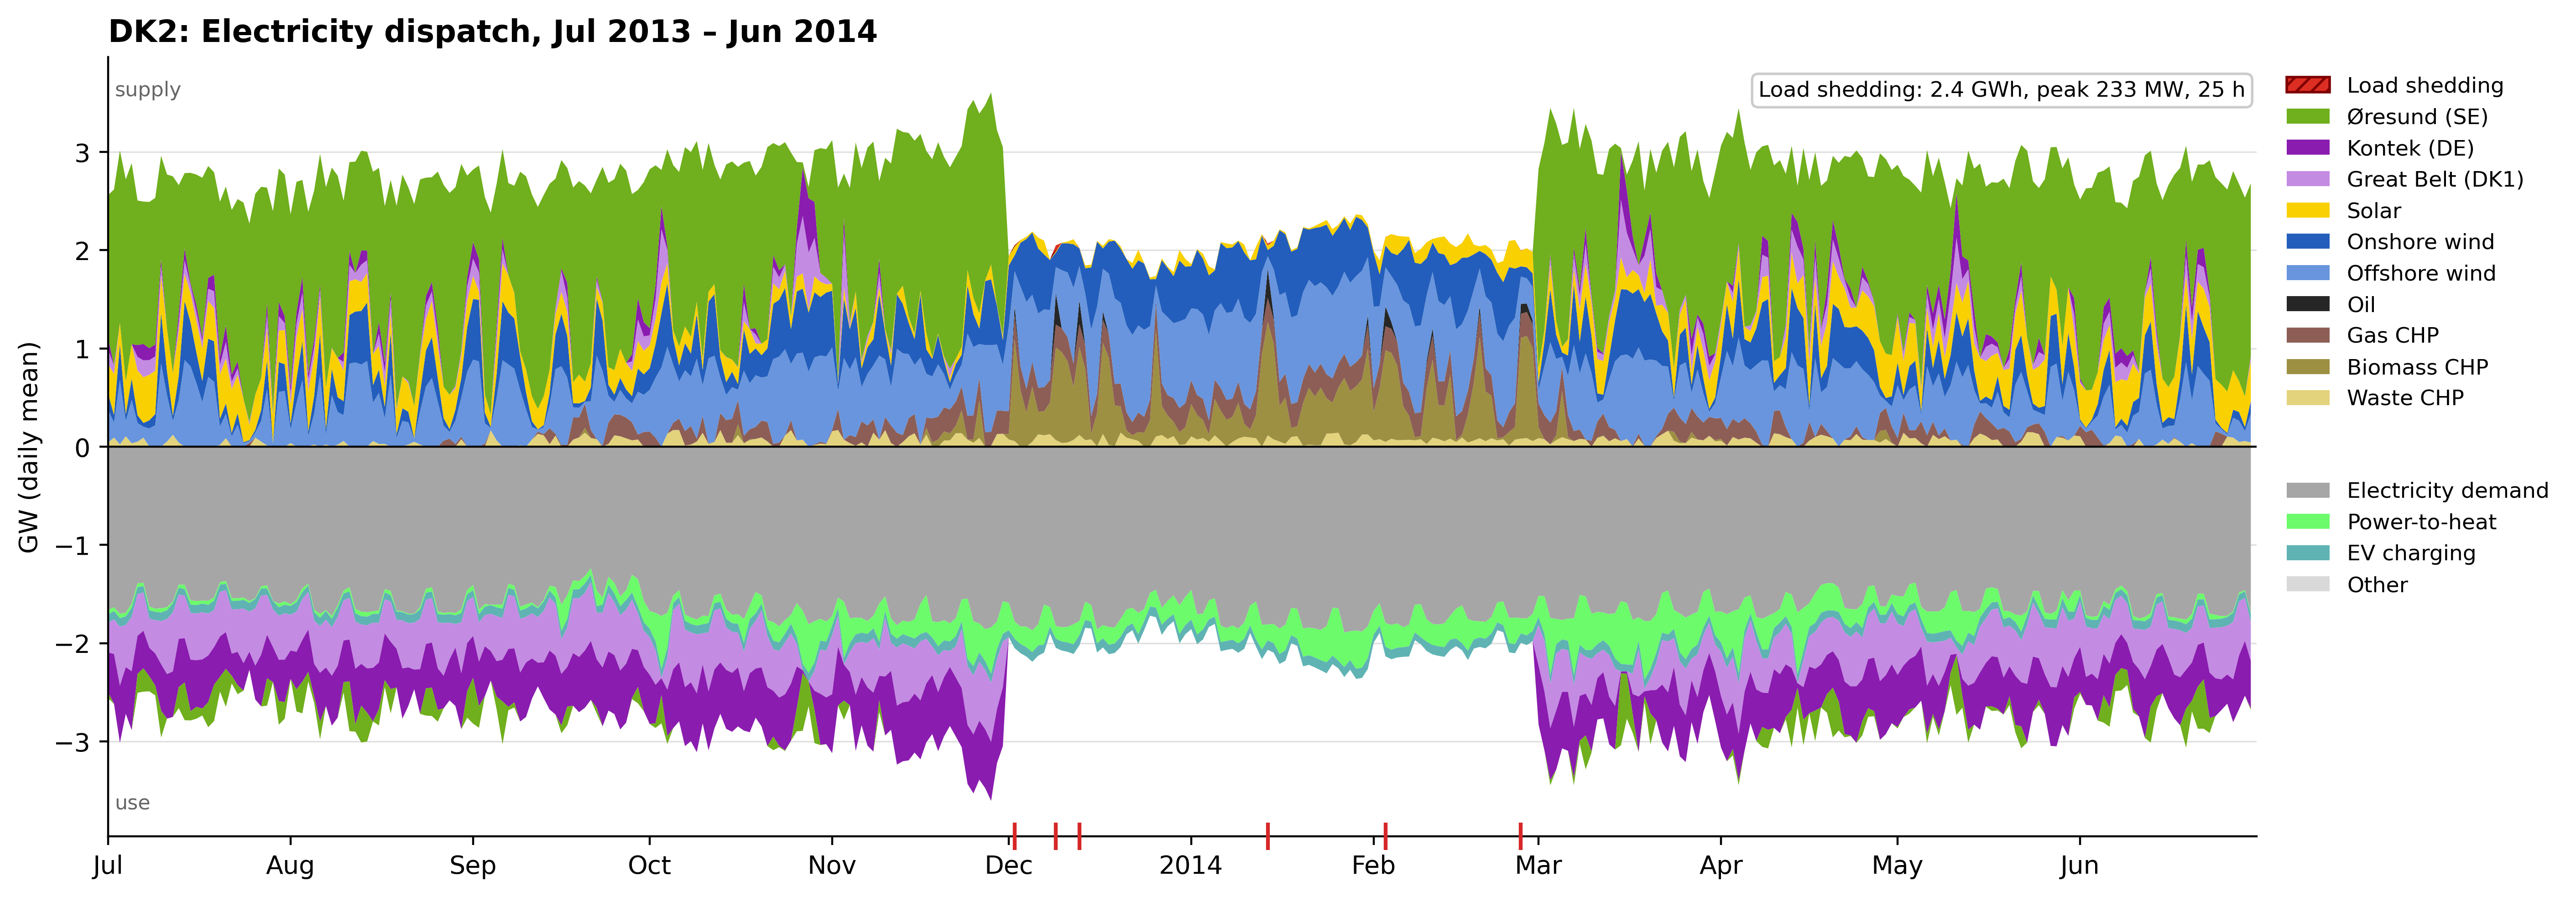

In [7]:
fig = plot_year(balances["power"], REGION_LABEL, "power")
save(fig, f"dispatch_year_{REGION_LABEL}_power", FIG_DIR)
plt.show()

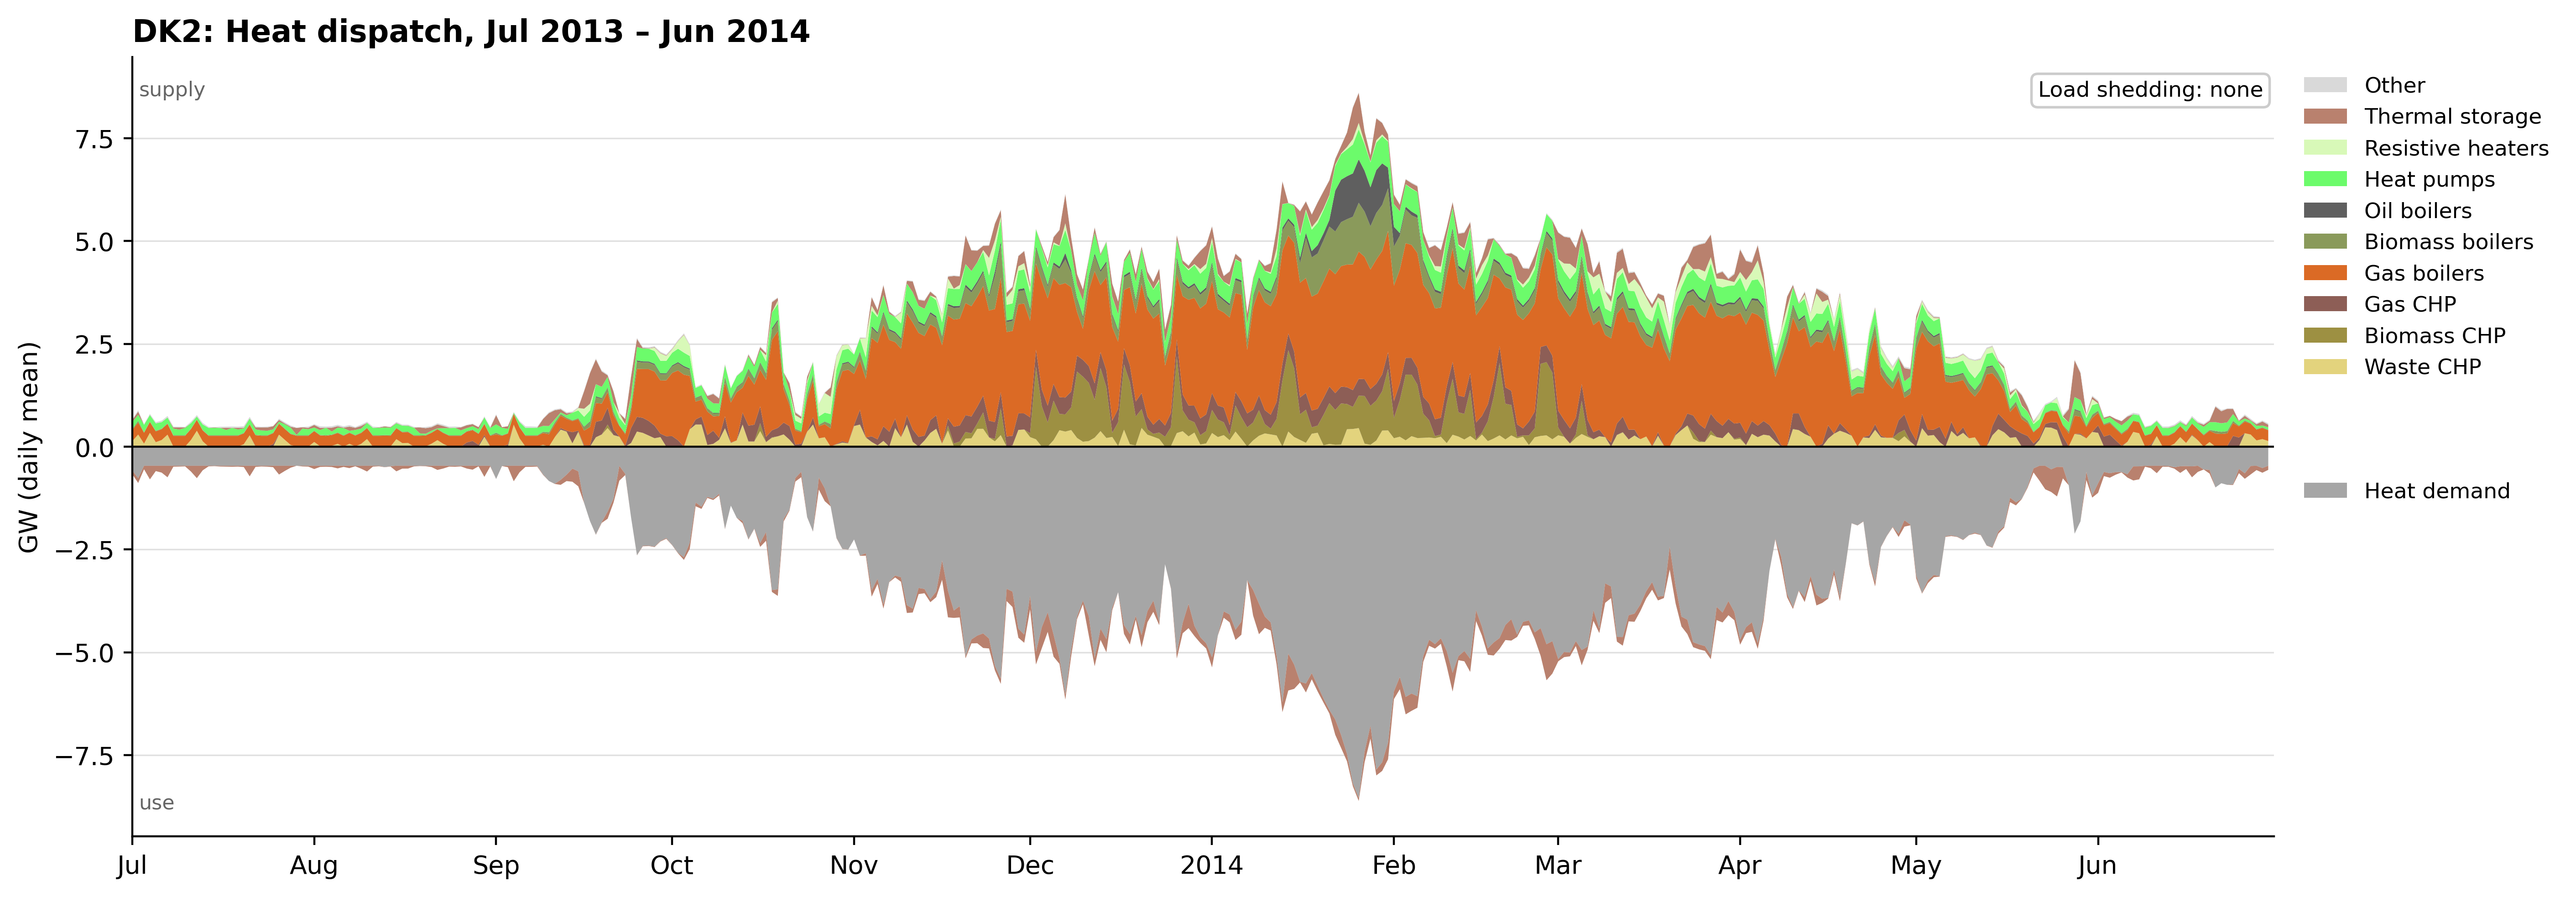

In [8]:
fig = plot_year(balances["heat"], REGION_LABEL, "heat")
save(fig, f"dispatch_year_{REGION_LABEL}_heat", FIG_DIR)
plt.show()

## Plot 2: summer vs. winter, hourly

Two-week windows from `ZOOM_WINDOWS`, side by side on the same y-scale so the seasons can be compared directly.

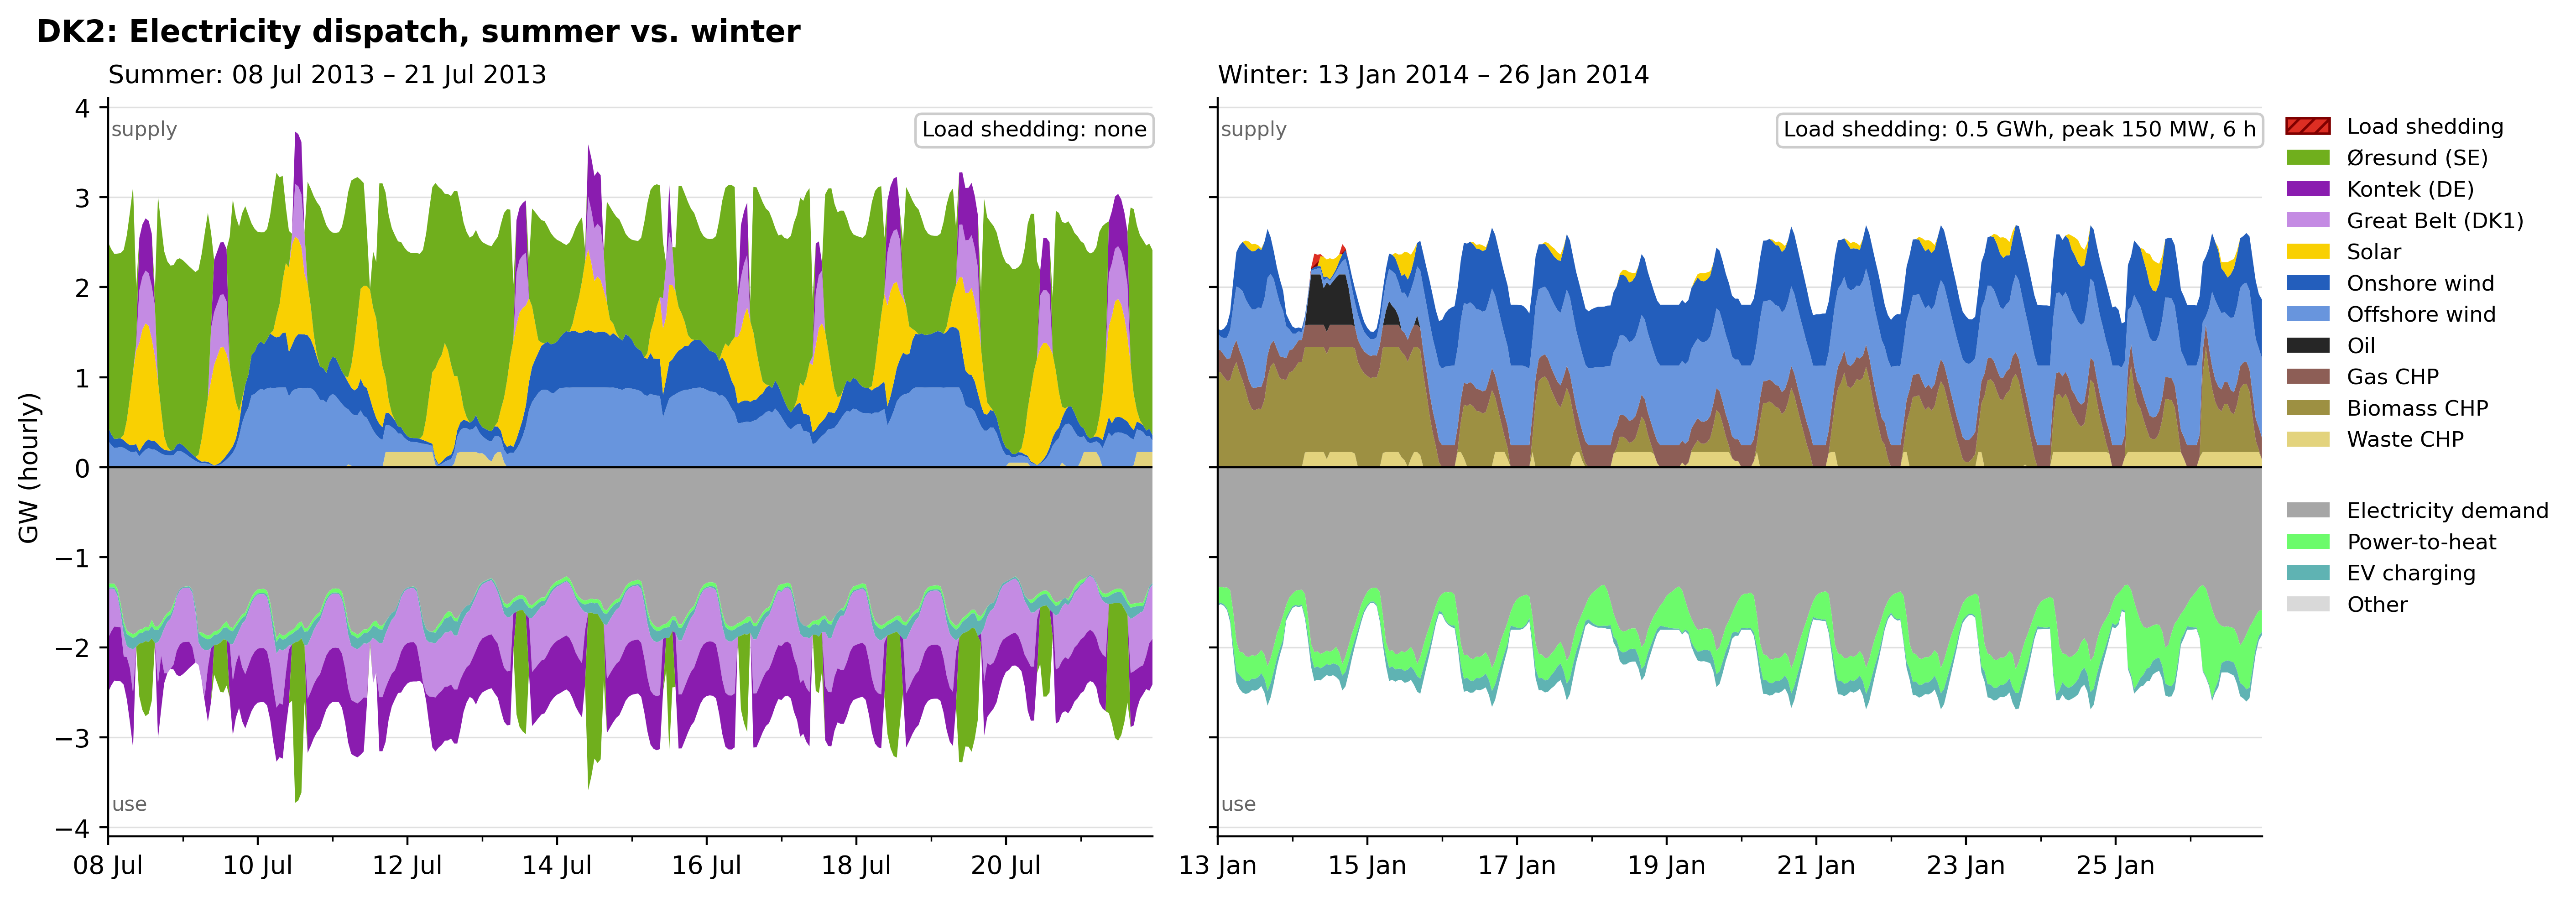

In [9]:
fig = plot_zoom(balances["power"], REGION_LABEL, "power")
save(fig, f"dispatch_zoom_{REGION_LABEL}_power", FIG_DIR)
plt.show()

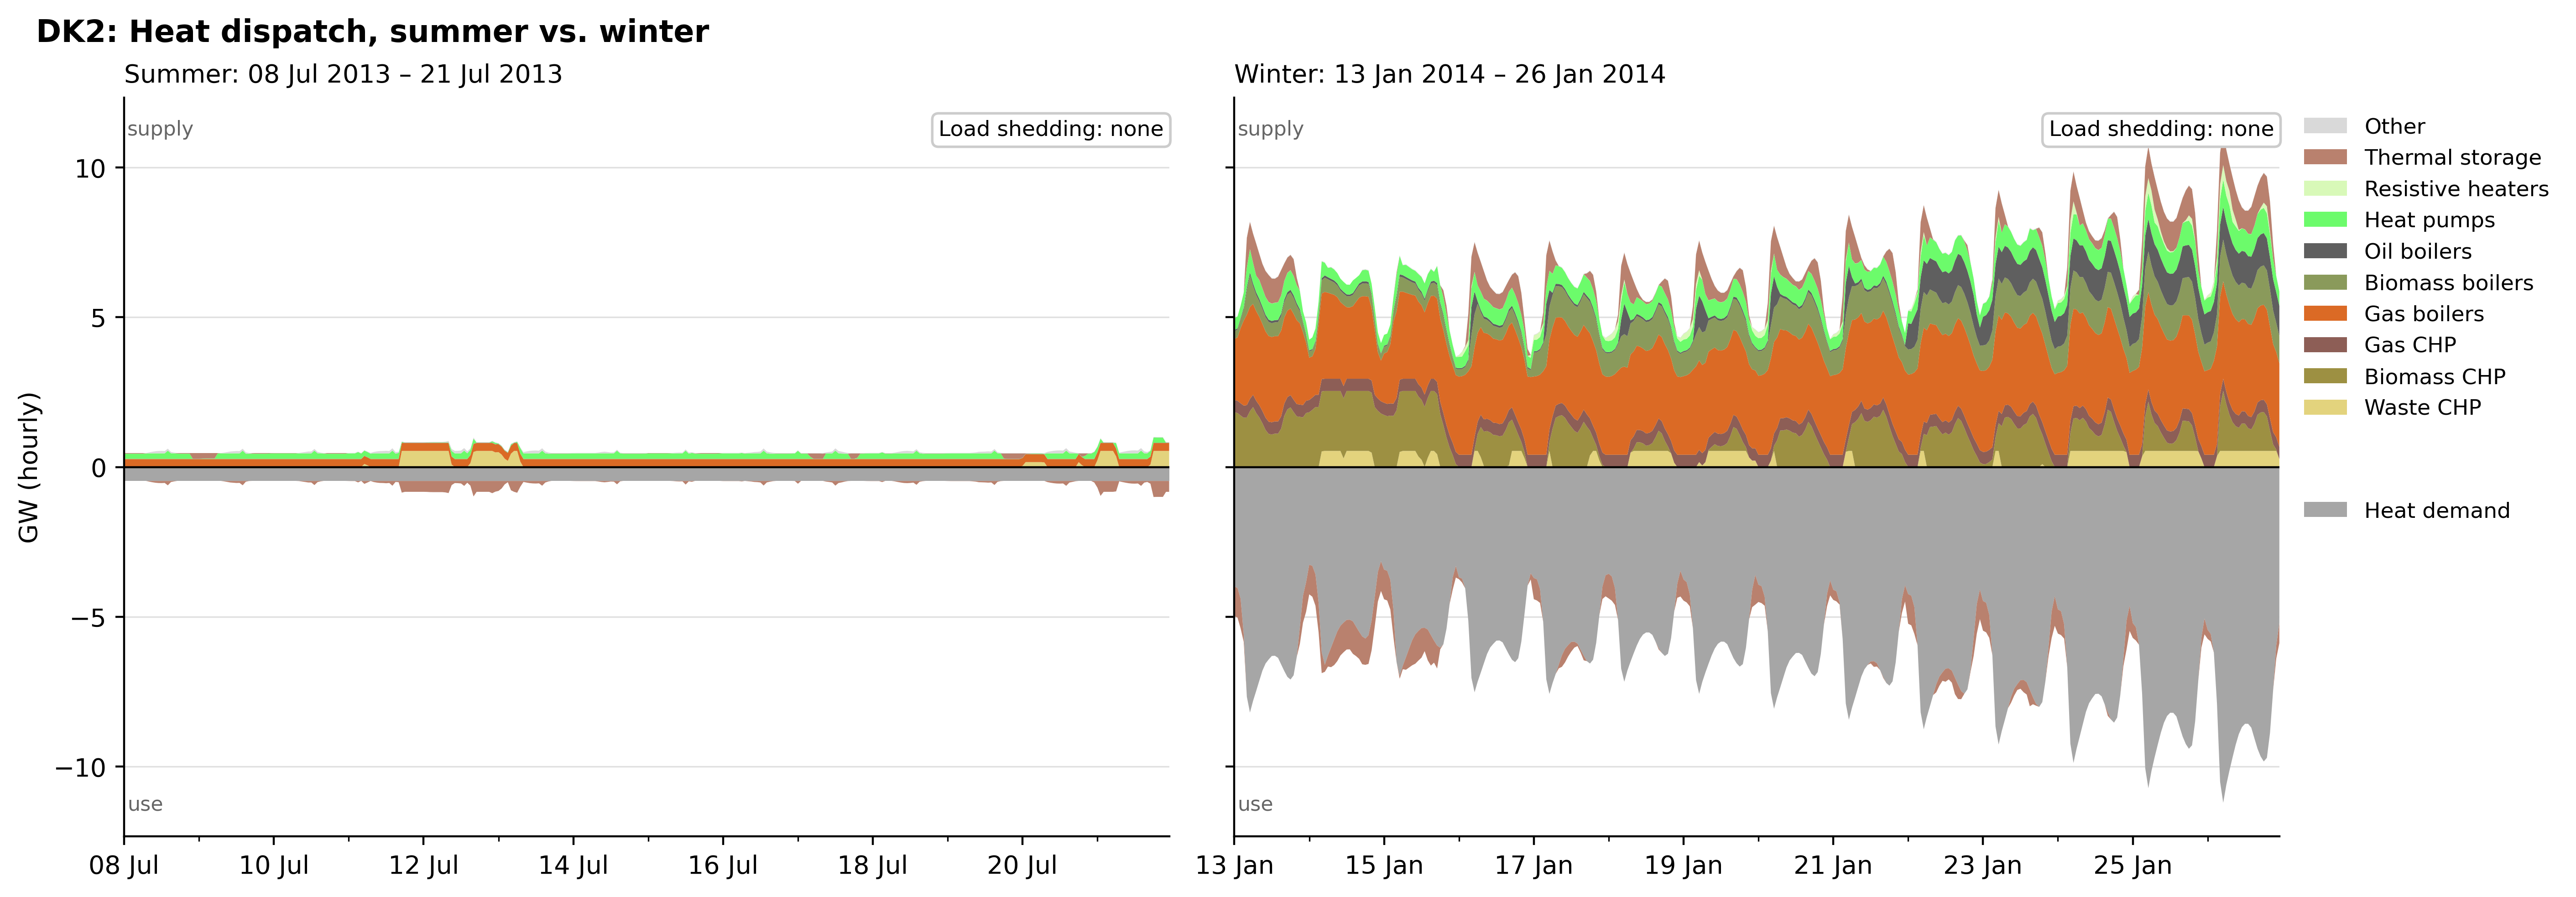

In [10]:
fig = plot_zoom(balances["heat"], REGION_LABEL, "heat")
save(fig, f"dispatch_zoom_{REGION_LABEL}_heat", FIG_DIR)
plt.show()

## Plot 3: how the demand is covered (annual shares)

Share of the year's demand covered by each local source and by **net imports** (imports − exports, summed over all cables). Demand = everything used in the region: fixed demand, power-to-heat, EVs, storage and grid losses. Generation + net imports (+ load shedding) = demand, so the bar sums to 100 %.

If the region is a **net exporter** over the year, local generation covers more than its demand: the bar then runs past the dashed 100 % line, and the title states the net exports as % of demand. Storage discharge is not a source (it only moves energy another source supplied).

In [11]:
NET_IMPORT_COLOR = "#546e7a"


def _text_color(hex_color):
    r, g, b = (int(hex_color.lstrip("#")[i:i + 2], 16) / 255 for i in (0, 2, 4))
    return "black" if 0.299 * r + 0.587 * g + 0.114 * b > 0.55 else "white"


def _pct(v):
    return f"{v:.1f} %" if v >= 0.1 else f"{v:.2f} %"


def demand_shares(bal):
    # Annual demand and the share (%) of it covered by each local source and by net imports.
    # Returns shares (%), demand (TWh), net flow per cable (TWh, + = import).
    ics = [g for g in bal if g in INTERCONNECTOR_NAMES.values() or g.startswith("Interconnectors ")]
    cable_twh = bal[ics].sum() / 1e6
    net_imports = cable_twh.sum()
    local = bal.drop(columns=ics + STORAGE_GROUPS, errors="ignore").clip(lower=0).sum() / 1e6
    local = local[local > 0]
    demand = local.sum() + net_imports

    shares = local / demand * 100
    # hide negligible sources (< 0.01 %), but always keep load shedding if it occurred
    shares = shares[(shares >= 0.01) | (shares.index == "Load shedding")]
    shares = shares[_ordered(shares.index, SUPPLY_ORDER, [])]
    if net_imports > 0:
        shares = pd.concat([shares.drop("Load shedding", errors="ignore"),
                            pd.Series({"Net imports": net_imports / demand * 100}),
                            shares.loc[shares.index == "Load shedding"]])
    return shares, demand, cable_twh


def plot_shares(bal, label, kind, min_inside=4.0):
    # One horizontal bar: share of the year's demand covered per source + net imports.
    shares, demand, cable_twh = demand_shares(bal)
    net_imports = cable_twh.sum()
    extra = iter(FALLBACK_COLORS)
    color = {g: NET_IMPORT_COLOR if g == "Net imports" else COLORS.get(g) or next(extra)
             for g in shares.index}

    fig, ax = plt.subplots(figsize=(14, 2.6), constrained_layout=True)
    left = 0.0
    for g, v in shares.items():
        kw = dict(hatch="////", edgecolor="#7f0000") if g == "Load shedding" else dict(edgecolor="white")
        text = f"{g}  {_pct(v)}"
        if g == "Net imports" and len(cable_twh):
            text += "  (" + ", ".join(f"{c.split(' (')[0]} {t:+.1f}" for c, t in cable_twh.items()) + " TWh)"
        ax.barh(0, v, left=left, height=0.6, color=color[g], linewidth=1.2, label=text, **kw)
        if v >= min_inside:
            ax.text(left + v / 2, 0, f"{v:.0f} %", ha="center", va="center",
                    fontsize=9, color=_text_color(color[g]))
        left += v

    title = (f"{label}: {KIND_TITLE[kind].lower()} demand by source, "
             f"{bal.index[0]:%b %Y} – {bal.index[-1]:%b %Y} (demand {demand:,.1f} TWh)")
    xmax = max(100.0, left)
    if net_imports < 0 and len(cable_twh):
        ax.axvline(100, color="black", ls="--", lw=1)
        ax.text(100, 0.42, " 100 % = demand", fontsize=8.5, va="bottom")
        title += f"\nnet exporter: net exports = {-net_imports / demand * 100:.1f} % of demand"
    ax.set_xlim(0, xmax)
    ax.set_ylim(-0.45, 0.55)
    ax.set_yticks([])
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0f} %"))
    for s in ("top", "right", "left"):
        ax.spines[s].set_visible(False)
    ax.set_title(title, loc="left", fontsize=12, fontweight="bold")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=min(len(shares), 4),
              frameon=False, fontsize=8.5)
    return fig, shares

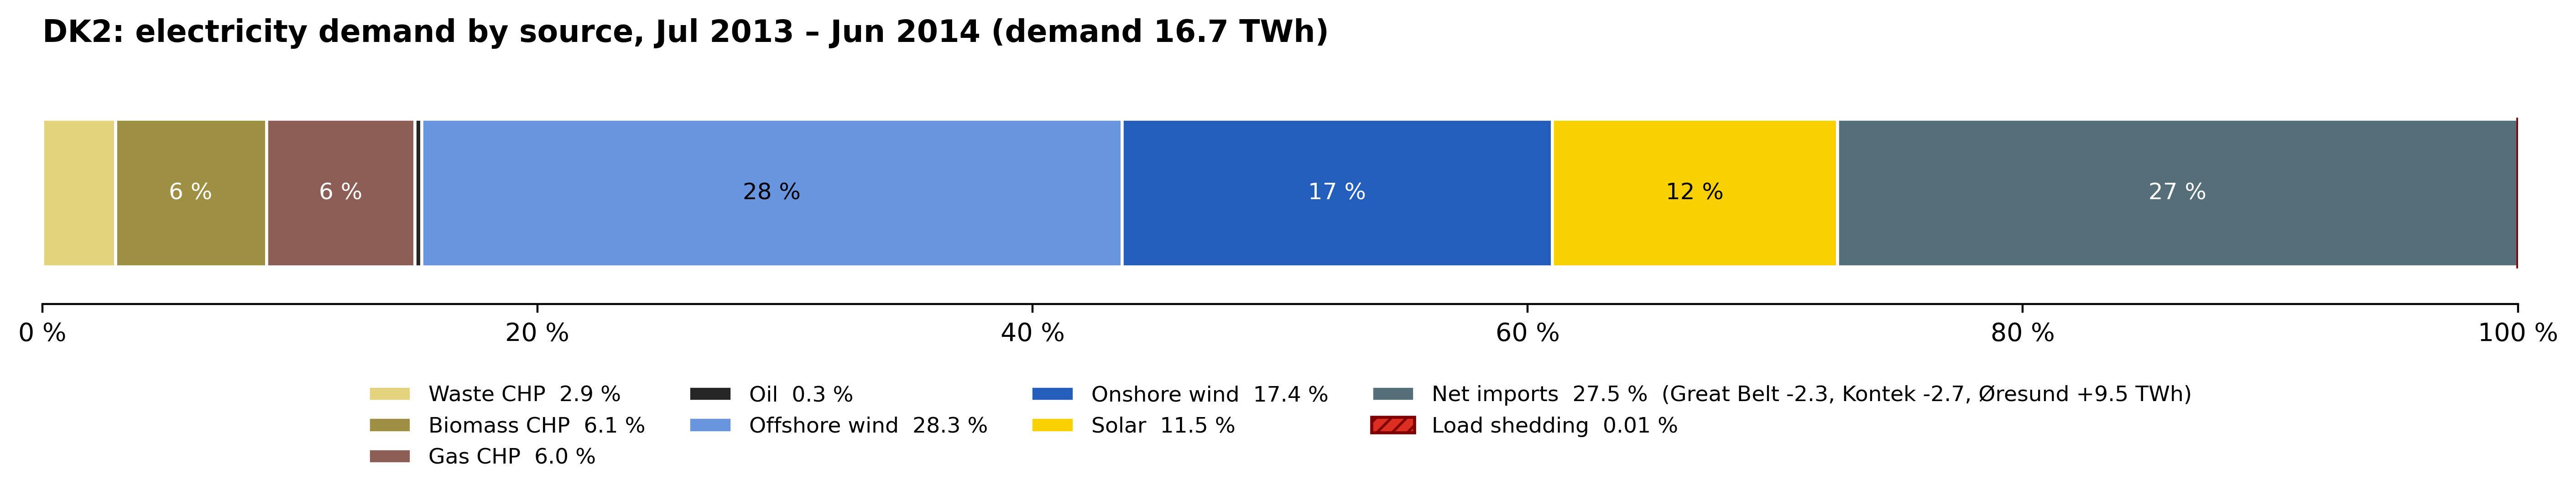

Waste CHP         2.9
Biomass CHP       6.1
Gas CHP           6.0
Oil               0.3
Offshore wind    28.3
Onshore wind     17.4
Solar            11.5
Net imports      27.5
Load shedding     0.0
dtype: float64

In [12]:
fig, shares = plot_shares(balances["power"], REGION_LABEL, "power")
save(fig, f"demand_shares_{REGION_LABEL}_power", FIG_DIR)
plt.show()
shares.round(1)

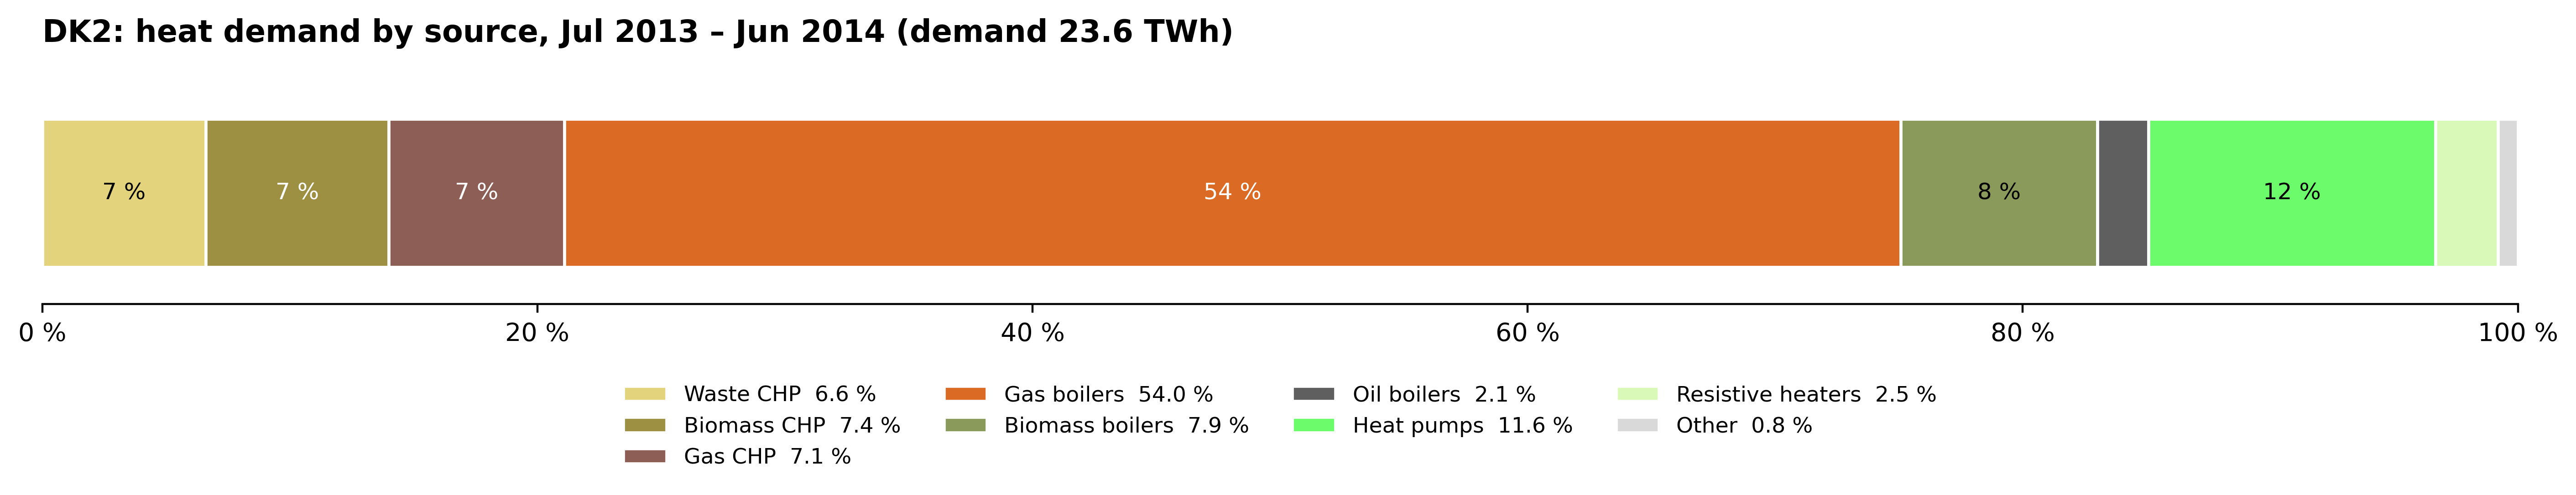

Waste CHP             6.6
Biomass CHP           7.4
Gas CHP               7.1
Gas boilers          54.0
Biomass boilers       7.9
Oil boilers           2.1
Heat pumps           11.6
Resistive heaters     2.5
Other                 0.8
dtype: float64

In [13]:
fig, shares = plot_shares(balances["heat"], REGION_LABEL, "heat")
save(fig, f"demand_shares_{REGION_LABEL}_heat", FIG_DIR)
plt.show()
shares.round(1)

## Annual totals

In [14]:
annual_table(balances)

supply TWh  use TWh
power Biomass CHP              1.018    0.000
      EV charging              0.000   -0.762
      Electricity demand       0.000  -14.350
      Gas CHP                  1.001    0.000
      Great Belt (DK1)         0.573   -2.845
      Kontek (DE)              0.397   -3.084
      Load shedding            0.002    0.000
      Offshore wind            4.718    0.000
      Oil                      0.046    0.000
      Onshore wind             2.902    0.000
      Power-to-heat            0.000   -1.571
      Solar                    1.920    0.000
      Waste CHP                0.491    0.000
      Øresund (SE)            10.072   -0.529
heat  Biomass CHP              1.744    0.000
      Biomass boilers          1.874    0.000
      Gas CHP                  1.674    0.000
      Gas boilers             12.746    0.000
      Heat demand              0.000  -23.548
      Heat pumps               2.737    0.000
      Oil boilers              0.490    0.000
      Other                    0.189    0.000
      Resistive heaters        0.595    0.000
      Thermal storage          1.207   -1.266
      Waste CHP                1.559    0.000